# Ramen on CIFAR-10-C at batch 100 reproduces the paper (72.6 vs 72.7); noise floor over seeds 0-4

*2026-11-02. Week 01. Plan: `docs/plans/week01_baseline.md`. First experiment on branch `pc2_lab` (upstream Ramen frozen at `ef0fdc7`, our code in `ramen_lab/`). Builds on nothing; every later CIFAR-10-C variant is compared with these runs.*

**Question.** What do zero-shot CLIP (NoAdapt) and Ramen score on CIFAR-10-C on PC2, through `ramen_lab`, and how much does Ramen move when only the stream order (the seed) changes?
**Hypothesis.** None. This is the baseline. Pre-registered red flags that would stop the week: NoAdapt depending on the seed, Ramen not being deterministic, Ramen ≤ NoAdapt, or a run tripping the RAM guard.

**Variants**
| name | class | config | what it changes | uses labels? |
|---|---|---|---|---|
| NoAdapt | upstream `NoAdapt` (`src/methods/NoAdapt.py`) | `cfg/default/NoAdapt.yaml` | nothing: zero-shot CLIP with a 7-template prompt ensemble | no |
| Ramen | upstream `Ramen` (`src/methods/Ramen.py`) | `cfg/CIFAR10C/Ramen.yaml`: $K$=7500, $k$=50, $\beta$=5, SignSGD $\eta$=0.01 | the baseline method | no |

**Data.** CIFAR-10-C, severity 5, the 15 main corruptions × 10,000 test images = 150,000 images, 10 classes. **Backbone.** CLIP ViT-B/32. **Batch.** 100, the paper's batch. The week-01 batch search found that it fits the 11 GB GPU 1 with Ramen's memory full (D18).
**Stream.** Mixed: all 15 corruptions shuffled into one stream. **Seeds.** 0-4 for Ramen, 0-1 for NoAdapt. A seed changes only the stream order (an explicit `torch.Generator(seed)` in `ramen_lab.stream`).
**GPUs.** Pre-registered map: seeds 0, 2, 4 on GPU 0 (RTX 3080 Ti); seeds 1, 3 on GPU 1 (RTX 2080 Ti). Later variants run each seed on the same GPU model as its baseline.
**How produced.** `python -m ramen_lab.launch --gpu {0,1} --ram-gb 8.2 -- baseline.py run CIFAR10C --seeds {0,2,4 | 1,3}` (see `baseline.py`), detached, one run per GPU, each under `ramen_lab`'s RAM guard (D17).
**What counts.** Numbers come from each run's `results/<run_id>/metrics.json`. The noise floor is 2 × (max − min) of Ramen's accuracy over seeds 0-4.

## How Ramen adapts (what every later experiment will change one term of)

For a batch $\{x_i\}_{i=1}^{B}$ ($B$ = 100), with CLIP's image encoder $f_\theta$, whose LayerNorm affine parameters $\theta$ (and only those) can adapt, starting from the pretrained $\theta_0$, and the text embeddings $W$ of the 10 class names (7-template ensemble):

**1. Embedding, zero-shot prediction, entropy** (`src/methods/Ramen.py:114-116`, `src/methods/losses.py:4`)
$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i)\rVert}, \qquad p_i = \mathrm{softmax}(100\, W^\top z_i), \qquad \hat y_i = \arg\max_c p_{ic}, \qquad H_i = -\sum_c p_{ic} \log p_{ic}$$

**2. Per-sample gradient** of the entropy with respect to the LayerNorm parameters, at $\theta_0$ (`Ramen.py:118-120`; per-sample LayerNorms in `src/models/ModelForBySampleTTA.py`):
$$g_i = \nabla_\theta H_i \big|_{\theta_0} \in \mathbb{R}^{D}, \qquad D = 39{,}936 \text{ for ViT-B/32}$$

**3. Memory write, before retrieval** (`Ramen.py:124-133`): $(z_i, g_i, H_i, t_i)$ goes into the queue $\mathcal{M}_{\hat y_i}$ of its zero-shot class, with $t_i$ its position in the stream. Each queue holds $K$ = 7,500 entries; when it is full, the entry with the smallest $t$ is replaced (FIFO; $t$ is stored in fp16).

**4. Retrieval and aggregation** (`Ramen.py:136-154`): from every non-empty queue $c$, the $k$ = 50 entries nearest to $z_i$:
$$w_{ij} = e^{-H_j}\, e^{-\beta\, \lVert z_i - z_j \rVert_2}, \qquad
G_i = \frac{1}{|\mathcal{C}^{+}|} \sum_{c \in \mathcal{C}^{+}} \; \sum_{j \in \mathrm{top}k_c(z_i)} w_{ij}\, g_j, \qquad \beta = 5$$
where $\mathcal{C}^{+}$ is the set of non-empty queues. Because step 3 comes first, $x_i$ retrieves itself (distance 0) and its batch-mates.

**5. One SignSGD step per sample, predict, reset** (`Ramen.py:157-168`, `src/models/optimizer.py:9`):
$$\theta_i = \theta_0 - \eta\, \mathrm{sign}(G_i), \quad \eta = 0.01, \qquad \text{prediction} = \arg\max_c \mathrm{softmax}\big(100\, W^\top f_{\theta_i}(x_i)\big)_c, \qquad \theta \leftarrow \theta_0$$

### What the batch size does in this derivation
$B$ appears nowhere in $G_i$. It matters in three places:
1. In step 3, the $B-1$ batch-mates are already in memory when $x_i$ retrieves.
2. The per-sample LayerNorm buffers are sized by $B$; this costs memory and doesn't change the math.
3. $t_i$ is the global stream position (`torch.arange(counter, counter + B)`), so the fp16 rounding of priorities, exact only up to 2,048, depends on the position, not on $B$.

At $B$ = 100 we use the paper's setting, so the reproduction gap below can't come from the batch size.

### How this could fail to reproduce, and what would show it
- A harness bug, e.g. a different stream or wrong labels. The tests show that `ramen_lab.Runner` gives the same predictions as upstream `Ramen` called directly (`tests/test_lab_runner.py`), and NoAdapt should match the paper's "Ensemble" row.
- Hidden randomness: two runs of the same seed would disagree. The subset check below tests this.
- Hardware: fp16 kernels differ between GPU models, so per-image predictions can differ across cards. Accuracy should not differ beyond the noise floor.

In [1]:
%load_ext autoreload
%autoreload 2
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[2]))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import baseline as B
from ramen_lab.analysis import plots, stats
plots.use_style()
pd.set_option('display.width', 200)
DS = 'CIFAR10C'
runs = B.seed_table(DS)
runs

,method,seed,gpu,acc,acc_micro,images,correct,minutes,peak_ram_gb,ram_budget_gb,peak_gpu_reserved_gb
0,NoAdapt,0,RTX 3080 Ti,61.3633,61.3633,150000,92045,1.19,6.81,8.2,0.67
1,NoAdapt,1,RTX 2080 Ti,61.3580,61.3580,150000,92037,1.43,6.34,8.2,0.62
2,Ramen,0,RTX 3080 Ti,72.6140,72.6140,150000,108921,3.60,7.30,8.2,9.82
3,Ramen,1,RTX 2080 Ti,72.5747,72.5747,150000,108862,6.43,6.58,8.2,9.45
4,Ramen,2,RTX 3080 Ti,72.6653,72.6653,150000,108998,3.62,7.26,8.2,9.82
5,Ramen,3,RTX 2080 Ti,72.5960,72.5960,150000,108894,6.71,7.22,8.2,7.95
6,Ramen,4,RTX 3080 Ti,72.5733,72.5733,150000,108860,3.62,7.23,8.2,9.82


## The data

Images per corruption and error counts of NoAdapt and Ramen at seed 0 (both on the RTX 3080 Ti, same stream), from the per-image records.

In [2]:
na, ra = B.paired_records(DS, seed=0)
names = B.PAPER_C10['corruptions']
data = pd.DataFrame({'images': np.bincount(na['domain_idx']),
                     'NoAdapt wrong': np.bincount(na['domain_idx'], weights=na['pred'] != na['label']).astype(int),
                     'Ramen wrong': np.bincount(ra['domain_idx'], weights=ra['pred'] != ra['label']).astype(int)},
                    index=names)
data.loc['total'] = data.sum()
for c in ('NoAdapt wrong', 'Ramen wrong'):
    data[c] = [f'{w:,} ({100 * w / n:.1f}%)' for w, n in zip(data[c], data['images'])]
data['images'] = data['images'].map('{:,}'.format)
print(f"classes: 10; images per class in the stream: {np.bincount(na['label']).min():,} to {np.bincount(na['label']).max():,}")
data

classes: 10; images per class in the stream: 15,000 to 15,000


,images,NoAdapt wrong,Ramen wrong
gaussian_noise,"10,000","6,137 (61.4%)","3,982 (39.8%)"
shot_noise,"10,000","5,733 (57.3%)","3,708 (37.1%)"
impulse_noise,"10,000","5,718 (57.2%)","4,378 (43.8%)"
defocus_blur,"10,000","2,741 (27.4%)","2,292 (22.9%)"
glass_blur,"10,000","5,612 (56.1%)","3,576 (35.8%)"
motion_blur,"10,000","3,329 (33.3%)","2,252 (22.5%)"
zoom_blur,"10,000","2,828 (28.3%)","2,124 (21.2%)"
snow,"10,000","2,618 (26.2%)","1,908 (19.1%)"
frost,"10,000","2,427 (24.3%)","1,991 (19.9%)"
fog,"10,000","3,107 (31.1%)","2,190 (21.9%)"


## Sanity checks

1. **Determinism and seed independence, on the same GPU** (subset check, 200 images per corruption = 3,000, GPU 0): NoAdapt seed 0 vs seed 1, and Ramen seed 0 run twice.
2. **The same comparison on the full stream across GPU models**: NoAdapt seed 0 ran on the 3080 Ti, seed 1 on the 2080 Ti.
3. **Resources** against the RAM budget (D17).

In [3]:
same_na, n = B.check_agreement('NoAdapt', 'a', 'a', (0, 1))
same_ra, _ = B.check_agreement('Ramen', 'a', 'b', (0, 0))
full_same, full_n = B.full_noadapt_agreement(DS)
print(f'subset, GPU 0: NoAdapt seed 0 vs 1 identical on {same_na:,} of {n:,} ({100 * same_na / n:.2f}%)')
print(f'subset, GPU 0: Ramen seed 0 twice identical on {same_ra:,} of {n:,} ({100 * same_ra / n:.2f}%)')
print(f'full stream, 3080 Ti vs 2080 Ti: NoAdapt seed 0 vs 1 identical on {full_same:,} of {full_n:,} '
      f'({100 * full_same / full_n:.2f}%); {full_n - full_same:,} predictions differ')
na_acc = runs[runs.method == 'NoAdapt'].set_index('seed')
print(f"NoAdapt accuracy: seed 0 {na_acc.acc[0]:.4f} (3080 Ti), seed 1 {na_acc.acc[1]:.4f} (2080 Ti): "
      f"{na_acc.correct[0] - na_acc.correct[1]:+,} correct images")
runs[['method', 'seed', 'gpu', 'minutes', 'peak_ram_gb', 'ram_budget_gb', 'peak_gpu_reserved_gb']]

subset, GPU 0: NoAdapt seed 0 vs 1 identical on 3,000 of 3,000 (100.00%)
subset, GPU 0: Ramen seed 0 twice identical on 3,000 of 3,000 (100.00%)
full stream, 3080 Ti vs 2080 Ti: NoAdapt seed 0 vs 1 identical on 149,376 of 150,000 (99.58%); 624 predictions differ
NoAdapt accuracy: seed 0 61.3633 (3080 Ti), seed 1 61.3580 (2080 Ti): +8 correct images


,method,seed,gpu,minutes,peak_ram_gb,ram_budget_gb,peak_gpu_reserved_gb
0,NoAdapt,0,RTX 3080 Ti,1.19,6.81,8.2,0.67
1,NoAdapt,1,RTX 2080 Ti,1.43,6.34,8.2,0.62
2,Ramen,0,RTX 3080 Ti,3.60,7.30,8.2,9.82
3,Ramen,1,RTX 2080 Ti,6.43,6.58,8.2,9.45
4,Ramen,2,RTX 3080 Ti,3.62,7.26,8.2,9.82
5,Ramen,3,RTX 2080 Ti,6.71,7.22,8.2,7.95
6,Ramen,4,RTX 3080 Ti,3.62,7.23,8.2,9.82


**Reading.** On one GPU, the seed doesn't change NoAdapt and Ramen is deterministic, both exactly, so no hidden randomness. Across the two GPU models, about 0.4% of per-image predictions differ (fp16 kernels), with a net effect on NoAdapt's accuracy far below a hundredth of a point. Per-image comparisons must therefore pair runs on the same GPU model, which the seed → GPU map ensures. Peak RAM of every run stayed under its 8.2 GB budget, but with less margin than intended (see Interpretation).

## Result 1: Ramen over seeds 0-4, and the noise floor

Ramen: mean 72.605, std 0.038, range 72.573 to 72.665
noise floor = 2 x (max - min) = 0.184 pts
Ramen - NoAdapt (seed 0): +11.25 pts


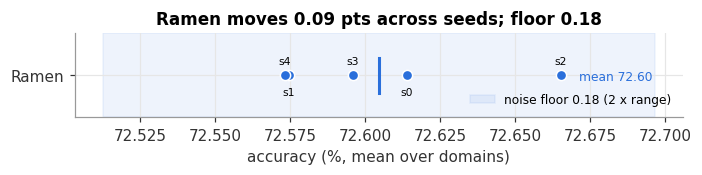

In [4]:
ramen = runs[runs.method == 'Ramen'].set_index('seed').acc
floor = stats.noise_floor(ramen.values)
print(f'Ramen: mean {ramen.mean():.3f}, std {ramen.std(ddof=1):.3f}, range {ramen.min():.3f} to {ramen.max():.3f}')
print(f'noise floor = 2 x (max - min) = {floor:.3f} pts')
print(f"Ramen - NoAdapt (seed 0): {ramen[0] - na_acc.acc[0]:+.2f} pts")
fig = plots.seed_accuracies({'Ramen': ramen.values}, list(ramen.index),
                            title=f'Ramen moves {ramen.max() - ramen.min():.2f} pts across seeds; floor {floor:.2f}',
                            floor=floor)

The floor spans both GPU models (seeds 0, 2, 4 on the 3080 Ti; 1, 3 on the 2080 Ti), so it includes hardware variation as well as stream order. That makes it conservative, which is the right direction for a bar a gain must clear.

## Result 2: the gap to the paper, per corruption

Paper (arXiv 2604.21728): Table 1, ViT-B/32 on CIFAR-10-C, mixture of 15 corruptions, batch 100. Ramen averages 72.7, and Table 5 gives its s.d. as 0.1. The zero-shot "Ensemble" row is 61.3.

average: ours 72.60 (seeds 0-4) vs paper 72.7 ± 0.1: -0.10 pts; NoAdapt ours 61.36 vs paper Ensemble 61.3


,NoAdapt,Ramen mean,Ramen min,Ramen max,seed range,paper Ramen,ours - paper,Ramen - NoAdapt
gaussian_noise,38.63,60.82,60.18,61.41,1.23,61.0,-0.18,22.19
shot_noise,42.67,63.22,62.92,63.60,0.68,63.3,-0.08,20.55
impulse_noise,42.82,55.97,55.57,56.30,0.73,56.0,-0.03,13.15
defocus_blur,72.59,77.10,77.02,77.18,0.16,77.2,-0.10,4.51
glass_blur,43.88,64.14,63.90,64.46,0.56,64.1,0.04,20.26
motion_blur,66.71,77.41,77.34,77.49,0.15,77.2,0.21,10.70
zoom_blur,71.72,78.77,78.64,78.87,0.23,78.9,-0.13,7.05
snow,73.82,80.76,80.56,80.92,0.36,80.9,-0.14,6.94
frost,75.73,80.12,79.91,80.42,0.51,80.3,-0.18,4.39
fog,68.93,78.02,77.88,78.15,0.27,78.0,0.02,9.09


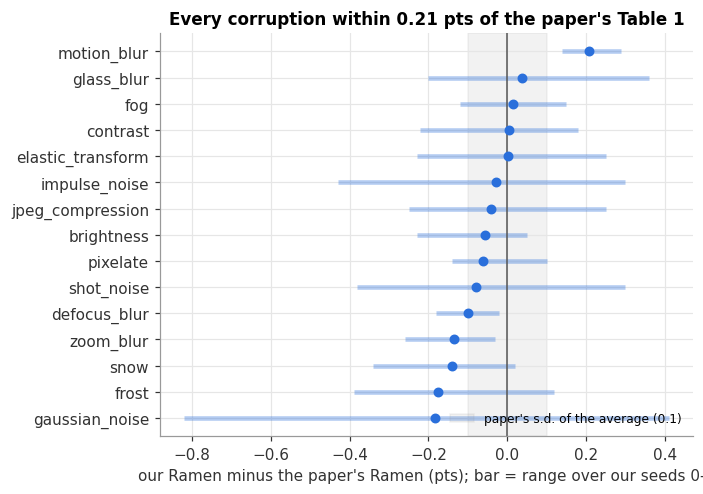

In [5]:
table = B.per_corruption(DS)
print(f"average: ours {ramen.mean():.2f} (seeds 0-4) vs paper {B.PAPER_C10['Ramen_avg']} ± {B.PAPER_C10['Ramen_avg_sd']}: "
      f"{ramen.mean() - B.PAPER_C10['Ramen_avg']:+.2f} pts; NoAdapt ours {na_acc.acc[0]:.2f} vs paper Ensemble {B.PAPER_C10['Ensemble_avg']}")
fig = B.plot_paper_gap(table, sd=B.PAPER_C10['Ramen_avg_sd'])
table.round(2)

## Result 3: where Ramen helps, per corruption and per image (seed 0)

{'fixed': '25,298 (16.9%)', 'broken': '8,422 (5.6%)', 'both right': '83,623 (55.7%)', 'both wrong': '32,657 (21.8%)'}


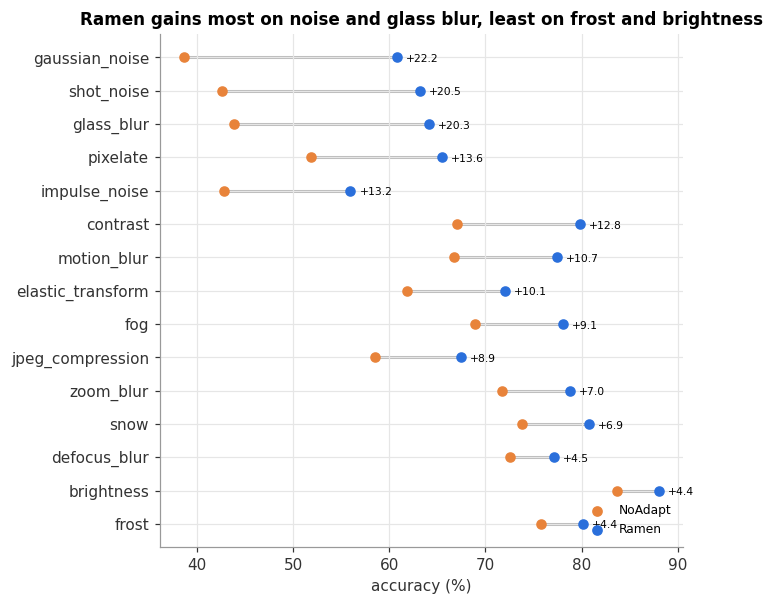

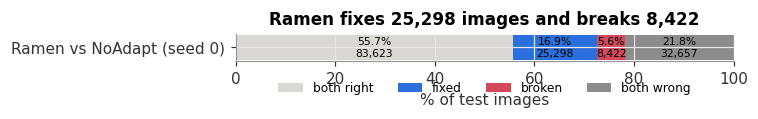

In [6]:
fig = plots.domain_dumbbell(table['NoAdapt'].to_dict(), table['Ramen mean'].to_dict(), ['NoAdapt', 'Ramen'],
                            title='Ramen gains most on noise and glass blur, least on frost and brightness')
out = stats.outcome_counts(ra['pred'] == ra['label'], na['pred'] == na['label'])
fig2 = plots.outcome_bars({'Ramen vs NoAdapt (seed 0)': out},
                          title=f"Ramen fixes {out['fixed']:,} images and breaks {out['broken']:,}")
print({k: f'{v:,} ({100 * v / len(na["label"]):.1f}%)' for k, v in out.items()})

## Result 4: accuracy along the stream (seed 0)

,start,end,NoAdapt,Ramen,gain
0,0,10000,60.80,70.64,9.84
1,10000,20000,61.43,72.13,10.70
2,20000,30000,62.31,72.85,10.54
3,30000,40000,61.73,72.68,10.95
4,40000,50000,60.94,72.48,11.54
5,50000,60000,61.78,72.39,10.61
6,60000,70000,60.66,72.47,11.81
7,70000,80000,61.15,73.28,12.13
8,80000,90000,60.87,72.16,11.29
9,90000,100000,61.58,73.22,11.64


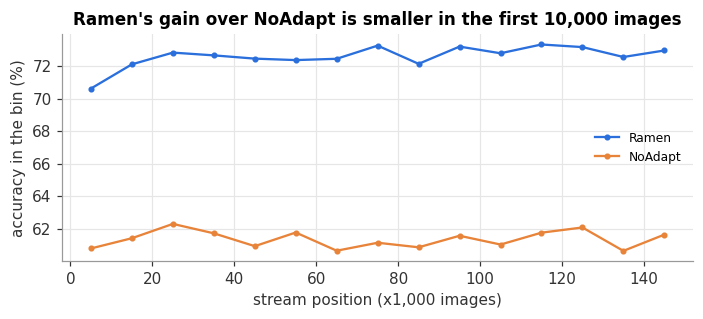

In [7]:
stream = B.over_stream(DS, seed=0)
fig = B.plot_over_stream(stream)
stream.assign(gain=stream.Ramen - stream.NoAdapt).round(2)

## Interpretation

**What the numbers say.**
- `ramen_lab` reproduces Ramen on CIFAR-10-C at the paper's batch: mean 72.60 over seeds 0-4, against 72.7 ± 0.1 in the paper.
- Every corruption is within 0.21 pts of the paper's Table 1. NoAdapt (61.36) matches the paper's prompt-ensemble row (61.3).
- The noise floor for CIFAR-10-C on `pc2_lab` is 0.18 pts. A variant must beat Ramen by at least that, paired per seed, before we call it a gain.
- None of the pre-registered red flags fired:
  - NoAdapt is seed-independent on one GPU;
  - Ramen is deterministic;
  - Ramen beats NoAdapt by about 11 pts;
  - no run tripped the RAM guard.

**What they don't say.**
- The floor is from five seeds on two GPU models, and per-corruption claims need that corruption's own seed range (1.23 pts on gaussian noise, see Result 2's table), which is much larger than the floor of the average.
- The paper's s.d. is over its own seeds and hardware [unverified: how many seeds, which GPU].
- This tells us nothing about the other datasets: their batches are still to be measured, and ImageNet-C uses ViT-B/16, not the paper's L/14.

**Mechanism, from the derivation.**
- Ramen's gain is largest where zero-shot is weakest (noise corruptions, glass blur), and smallest where zero-shot is already above 75% (frost, brightness, defocus).
- The first 10,000 images gain less than the rest (Result 4). That fits step 4: early queues hold few entries, so $G_i$ averages fewer, less similar neighbours. This cold-memory effect matches the legacy finding in `docs/research_state.md` [hypothesis on this branch: not tested by a controlled run].

**Resources.**
- Peak RAM per run was 6.3-7.3 GB against a budget of 8.2 GB. The budget came from 1.5 × the subset smoke run (5.48 GB), and the full stream used more.
- Next step: raise CIFAR-10-C's budget to about 1.5 × the full-run peak (about 11 GB) before running variants, so a slightly heavier variant isn't stopped by a margin that was too tight.

**Next.**
1. Batch search for CIFAR-100-C, ImageNet-C and DomainNet (D18).
2. Then the first idea, screened on CIFAR-10-C seed 0 against this floor, with its pre-registered gate.

## Glossary

- **NoAdapt / zero-shot CLIP**: CLIP's predictions without any adaptation. Text embeddings are the average over 7 prompt templates (the paper's "Ensemble").
- **Mixed stream**: all 15 corruptions shuffled into one test stream, so neighbouring images usually come from different corruptions.
- **Seed**: here, only the order of the stream (a seeded DataLoader shuffle). Upstream methods draw no random numbers.
- **Noise floor**: 2 × (max − min) of Ramen's mean accuracy over seeds 0-4. A variant's gain must exceed it.
- **Fixed / broken**: per image, wrong under NoAdapt and right under Ramen (fixed), or the reverse (broken).
- **$z_i$**: L2-normalised image embedding. **$g_i$**: per-sample gradient of the entropy $H_i$ with respect to the LayerNorm parameters. **$G_i$**: the retrieved, weighted, class-averaged gradient. **$w_{ij}$**: retrieval weight, $e^{-H_j} e^{-\beta d_{ij}}$.
- **$K$**: entries per class queue (7,500). **$k$**: neighbours retrieved per queue (50). **$\beta$**: distance temperature (5). **$\eta$**: SignSGD step (0.01).
- **Episodic per batch**: Ramen adapts, predicts, then restores the pretrained weights, so only the memory carries over between batches.
- **fp16 priority**: the stream position stored in half precision, exact up to 2,048. FIFO order is coarse after that.
- **PSS**: proportional set size, the memory measure the RAM guard uses; pages shared between DataLoader workers are split between them, not counted once per worker.